In [1]:
import pandas as pd
import numpy as np
import json
import ast
from pathlib import Path

# Resolve the checkout from either the project root or research/notebooks.
PROJECT_ROOT = next(
    p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (p / "run.py").is_file() and (p / "backend").is_dir()
)

import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True

CSV_PATH = PROJECT_ROOT / ".local/full.csv"

print("Fichier existe :", CSV_PATH.exists())
print("Chemin :", CSV_PATH)

Fichier existe : True
Chemin : /Users/ayatbouhrir/Desktop/STAAGE/code_source_mateo/stage-ayat-pfas-3ca5e26bbea506c8b7e15a98bc4b514bae610984/full.csv


In [2]:
# Chargement complet
df = pd.read_csv(CSV_PATH, low_memory=False)

print("Dimensions :", df.shape)
print("\nAperçu :")
display(df.head())

Dimensions : (622669, 21)

Aperçu :


,category,lat,lon,name,city,country,type,sector,source_type,data_collection_method,...,source_url,dataset_id,dataset_name,pfas_values,unit,pfas_sum,details,matrix,date,year
0,Known PFAS user,45.864286,5.948318,Fortier Beaulieu,Rumilly,France,Industrial site,NaN,Authorities,OSINT,...,https://www.auvergne-rhone-alpes.ars.sante.fr/...,0,Known PFAS Users,[],NaN,NaN,{},NaN,NaN,NaN
1,Known PFAS user,45.838896,5.960591,Salomon,Rumilly,France,Industrial site,NaN,Authorities,OSINT,...,https://www.auvergne-rhone-alpes.ars.sante.fr/...,0,Known PFAS Users,[],NaN,NaN,{},NaN,NaN,NaN
2,Known PFAS user,46.566759,4.904980,Tefal,Tournus,France,Industrial site,NaN,Authorities,OSINT,...,https://www.georisques.gouv.fr/risques/registr...,0,Known PFAS Users,[],NaN,NaN,{},NaN,NaN,NaN
3,Known PFAS user,47.984030,14.272978,Agru,Waldneukirchen,Austria,Industrial site,Manufacture of rubber and plastic products,Company,OSINT,...,https://www.agru.at/en/,0,Known PFAS Users,[],NaN,NaN,"{""maps_link"": ""https://goo.gl/maps/cSD9QcvjzUh...",NaN,NaN,NaN
4,Known PFAS user,48.032000,14.225225,Agru,Bad Hall,Austria,Industrial site,Manufacture of rubber and plastic products,Company,OSINT,...,https://www.agru.at/en/,0,Known PFAS Users,[],NaN,NaN,"{""maps_link"": ""https://goo.gl/maps/NkuHEHiEQbV...",NaN,NaN,NaN


In [3]:
print("Nombre de lignes :", len(df))
print("Nombre de colonnes :", len(df.columns))
print("\nColonnes :")
print(df.columns.tolist())

print("\nTypes bruts :")
print(df.dtypes)

print("\nMémoire utilisée (MB) :", round(df.memory_usage(deep=True).sum() / 1024**2, 2))

print("\nDoublons exacts :", df.duplicated().sum())

Nombre de lignes : 622669
Nombre de colonnes : 21

Colonnes :
['category', 'lat', 'lon', 'name', 'city', 'country', 'type', 'sector', 'source_type', 'data_collection_method', 'source_text', 'source_url', 'dataset_id', 'dataset_name', 'pfas_values', 'unit', 'pfas_sum', 'details', 'matrix', 'date', 'year']

Types bruts :
category                   object
lat                       float64
lon                       float64
name                       object
city                       object
country                    object
type                       object
sector                     object
source_type                object
data_collection_method     object
source_text                object
source_url                 object
dataset_id                  int64
dataset_name               object
pfas_values                object
unit                       object
pfas_sum                  float64
details                    object
matrix                     object
date                       object

In [4]:
schema_rows = []

for col in df.columns:
    series = df[col]
    non_null = series.notna().sum()
    missing = series.isna().sum()
    missing_pct = round((missing / len(df)) * 100, 2)
    nunique = series.nunique(dropna=True)
    
    sample_values = series.dropna().astype(str).head(3).tolist()
    sample_values = " | ".join(sample_values)
    
    schema_rows.append({
        "column": col,
        "dtype_pandas": str(series.dtype),
        "non_null_count": non_null,
        "missing_count": missing,
        "missing_pct": missing_pct,
        "n_unique": nunique,
        "sample_values": sample_values
    })

schema_df = pd.DataFrame(schema_rows).sort_values(by=["missing_pct", "n_unique"], ascending=[False, False])

display(schema_df)

,column,dtype_pandas,non_null_count,missing_count,missing_pct,n_unique,sample_values
7,sector,object,6012,616657,99.03,13,Manufacture of rubber and plastic products | M...
4,city,object,465871,156798,25.18,34491,Rumilly | Rumilly | Tournus
2,lon,float64,583445,39224,6.30,87759,5.948318 | 5.960591 | 4.90498
1,lat,float64,583445,39224,6.30,83919,45.864286 | 45.838896 | 46.566759
9,data_collection_method,object,591344,31325,5.03,6,OSINT | OSINT | OSINT
19,date,object,599000,23669,3.80,5525,2019-07-18 | 2019-07-22 | 2019-07-10
11,source_url,object,600714,21955,3.53,322,https://www.auvergne-rhone-alpes.ars.sante.fr/...
16,pfas_sum,float64,610027,12642,2.03,29544,130.0 | 200.0 | 42400.0
20,year,float64,610027,12642,2.03,34,2018.0 | 2017.0 | 2016.0
18,matrix,object,610027,12642,2.03,14,Surface water | Surface water | Surface water


In [5]:
output_schema = CSV_PATH.parent / "schema_dataset.csv"
schema_df.to_csv(output_schema, index=False)

print("Schéma sauvegardé dans :", output_schema)

Schéma sauvegardé dans : /Users/ayatbouhrir/Desktop/STAAGE/code_source_mateo/stage-ayat-pfas-3ca5e26bbea506c8b7e15a98bc4b514bae610984/schema_dataset.csv


In [8]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
object_cols = df.select_dtypes(include=["object"]).columns.tolist()
datetime_like_cols = [c for c in df.columns if "date" in c.lower() or "time" in c.lower() or "year" in c.lower()]

print("Colonnes numériques :", numeric_cols)
print("\nColonnes textuelles/object :", object_cols)
print("\nColonnes potentiellement temporelles :", datetime_like_cols)

Colonnes numériques : ['lat', 'lon', 'dataset_id', 'pfas_sum', 'year']

Colonnes textuelles/object : ['category', 'name', 'city', 'country', 'type', 'sector', 'source_type', 'data_collection_method', 'source_text', 'source_url', 'dataset_name', 'pfas_values', 'unit', 'details', 'matrix', 'date']

Colonnes potentiellement temporelles : ['date', 'year']


In [9]:
missing_df = (
    df.isna()
      .mean()
      .mul(100)
      .round(2)
      .sort_values(ascending=False)
      .reset_index()
)

missing_df.columns = ["column", "missing_pct"]
display(missing_df.head(20))

,column,missing_pct
0,sector,99.03
1,city,25.18
2,lon,6.30
3,lat,6.30
4,data_collection_method,5.03
5,date,3.80
6,source_url,3.53
7,year,2.03
8,unit,2.03
9,matrix,2.03


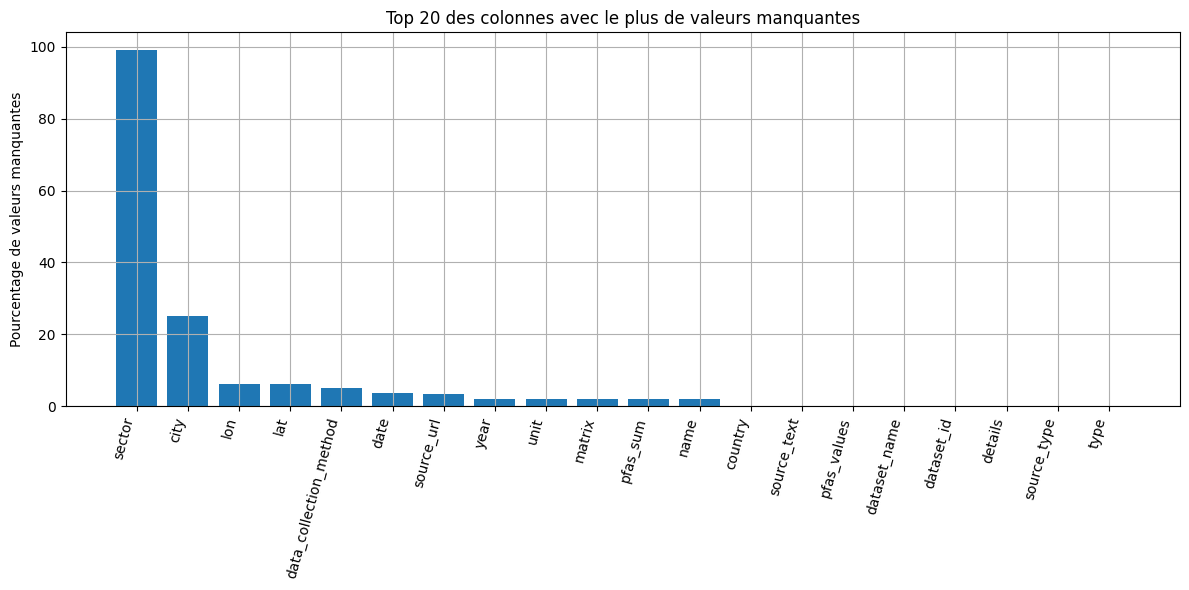

In [10]:
top_missing = missing_df.head(20)

plt.figure(figsize=(12, 6))
plt.bar(top_missing["column"], top_missing["missing_pct"])
plt.xticks(rotation=75, ha="right")
plt.ylabel("Pourcentage de valeurs manquantes")
plt.title("Top 20 des colonnes avec le plus de valeurs manquantes")
plt.tight_layout()
plt.show()

In [11]:
if numeric_cols:
    display(df[numeric_cols].describe().T)
else:
    print("Aucune colonne numérique détectée.")

,count,mean,std,min,25%,50%,75%,max
lat,583445.0,47.800411,6.514976e+00,-21.382742,45.614323,48.280970,50.877780,8.405050e+01
lon,583445.0,4.123244,7.253810e+00,-61.791256,0.996592,4.024303,6.059641,1.216080e+02
dataset_id,622669.0,53.290903,4.167367e+01,0.000000,28.000000,28.000000,94.000000,1.420000e+02
pfas_sum,610027.0,25690.161737,2.109474e+06,0.000000,0.000000,0.000000,8.700000,8.002451e+08
year,610027.0,2019.298390,4.352127e+00,1977.000000,2016.000000,2020.000000,2023.000000,2.026000e+03


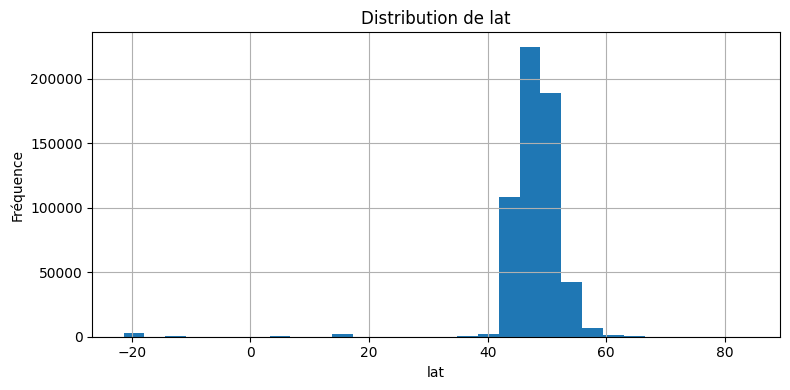

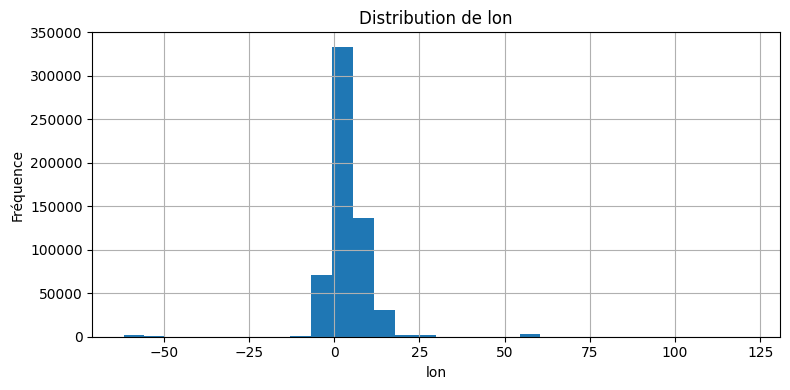

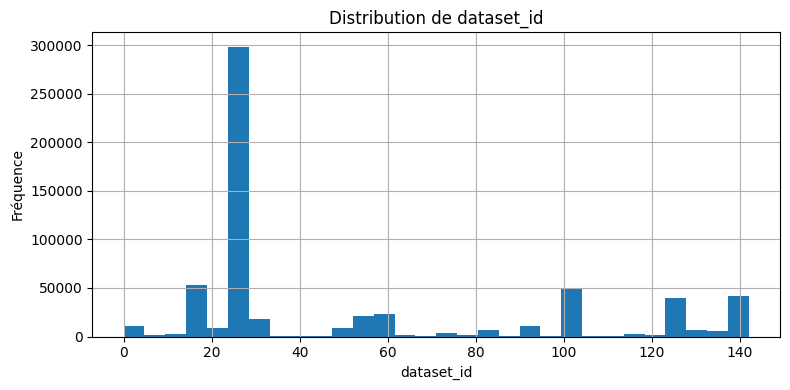

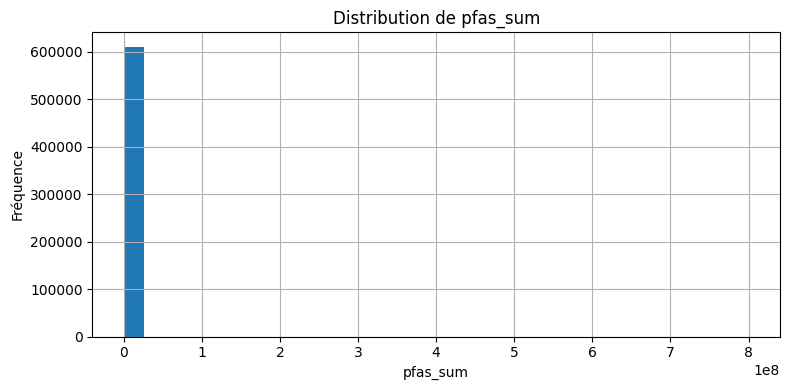

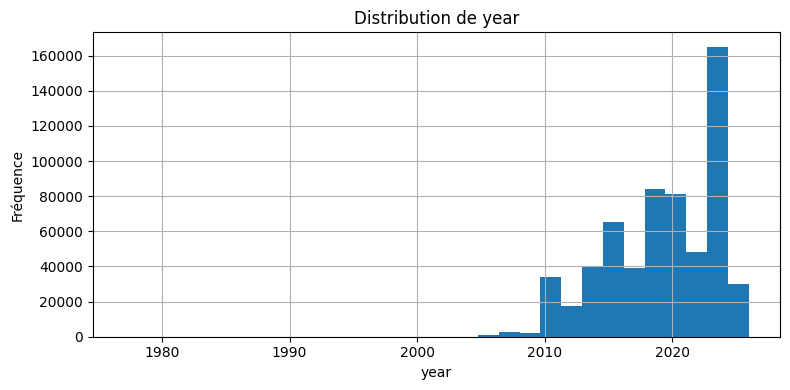

In [12]:
if numeric_cols:
    for col in numeric_cols:
        series = df[col].dropna()
        if len(series) == 0:
            continue
        
        plt.figure(figsize=(8, 4))
        plt.hist(series, bins=30)
        plt.title(f"Distribution de {col}")
        plt.xlabel(col)
        plt.ylabel("Fréquence")
        plt.tight_layout()
        plt.show()
else:
    print("Aucune colonne numérique à visualiser.")

In [13]:
categorical_cols = []

for col in object_cols:
    nunique = df[col].nunique(dropna=True)
    if 1 < nunique <= 50:  # seuil raisonnable pour catégoriel
        categorical_cols.append(col)

print("Colonnes catégorielles probables :", categorical_cols)

Colonnes catégorielles probables : ['category', 'country', 'type', 'sector', 'source_type', 'data_collection_method', 'unit', 'matrix']


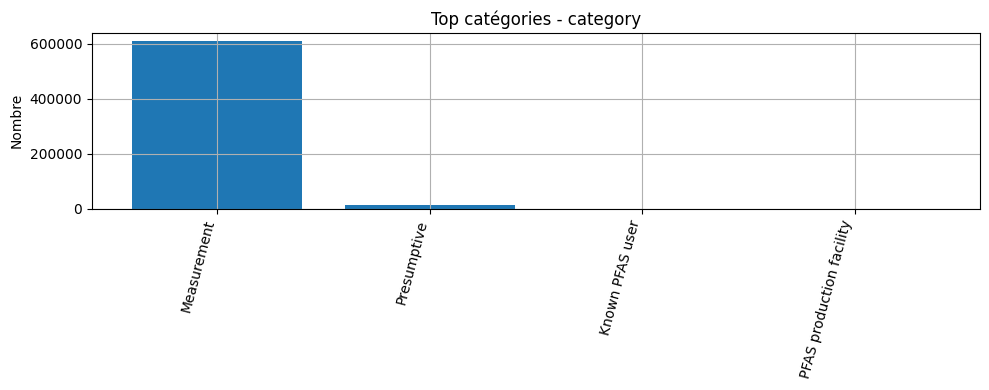

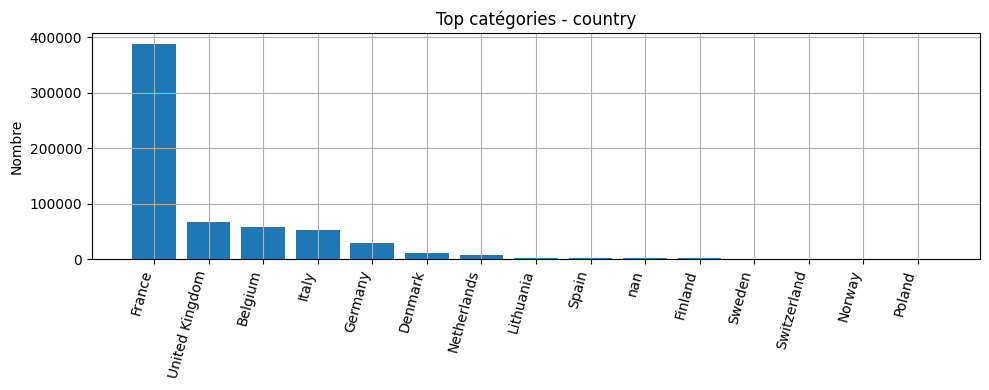

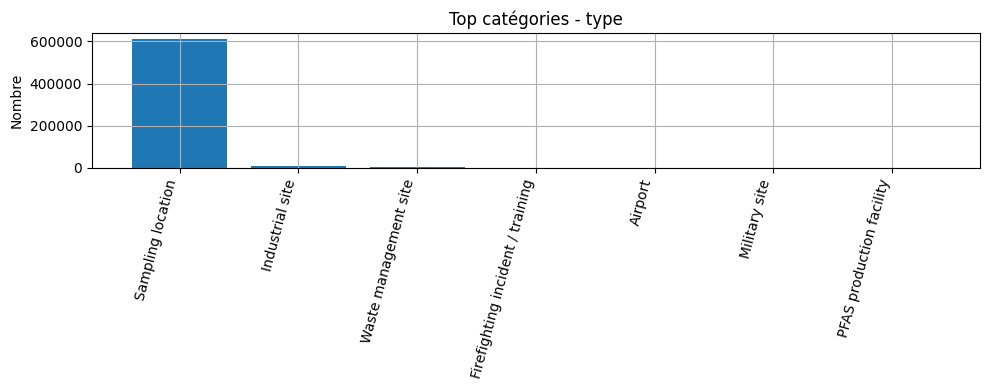

/var/folders/3g/yrxv3k6d243dsdl11k_hwsgm0000gn/T/ipykernel_45936/863009744.py:9: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


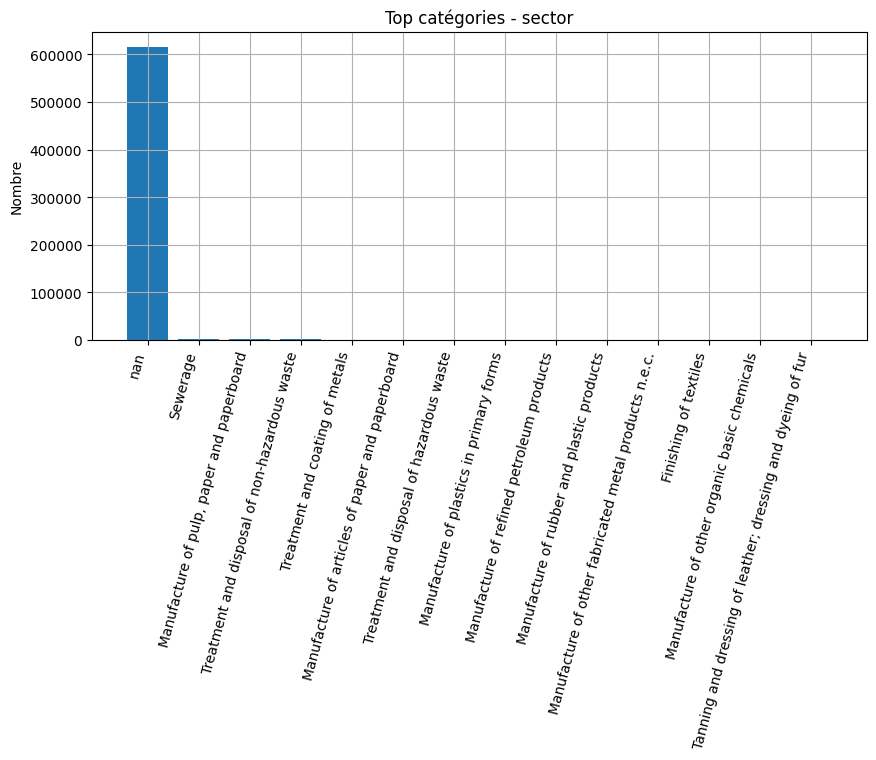

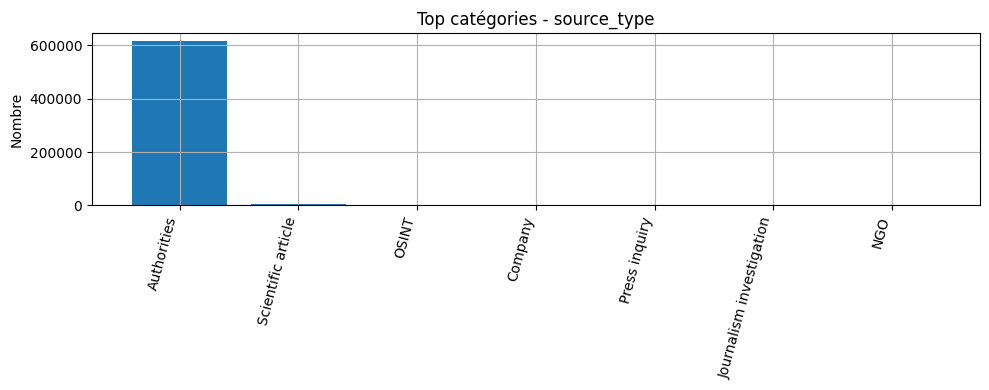

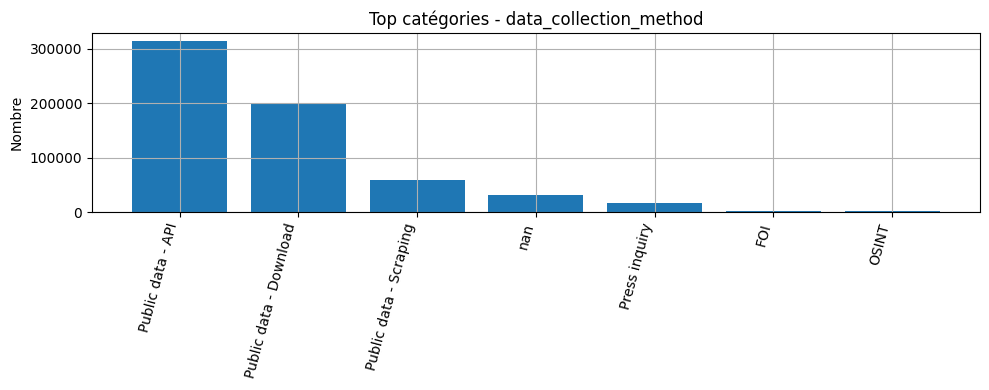

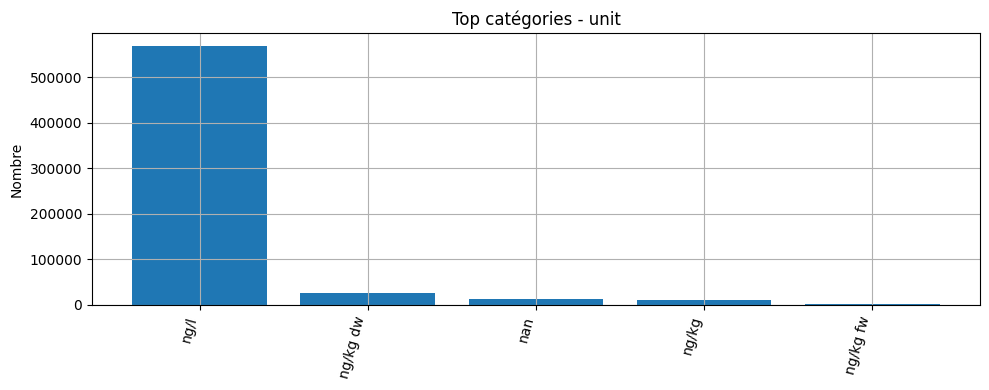

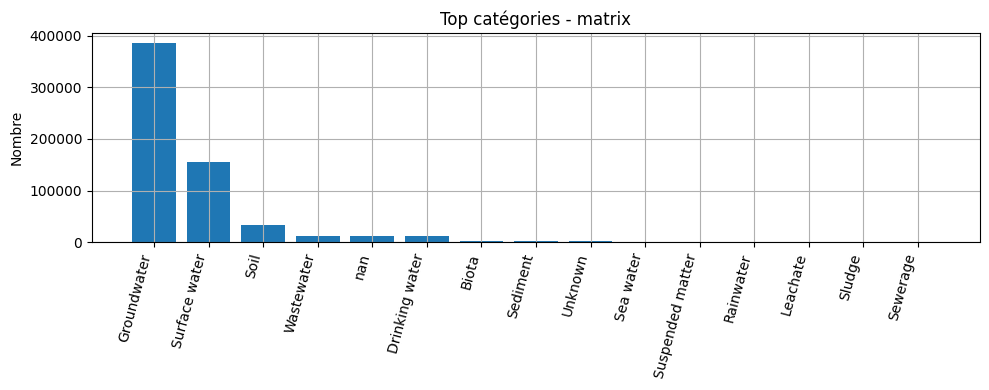

In [14]:
for col in categorical_cols:
    vc = df[col].value_counts(dropna=False).head(15)
    
    plt.figure(figsize=(10, 4))
    plt.bar(vc.index.astype(str), vc.values)
    plt.title(f"Top catégories - {col}")
    plt.xticks(rotation=75, ha="right")
    plt.ylabel("Nombre")
    plt.tight_layout()
    plt.show()

In [15]:
date_cols = [c for c in df.columns if "date" in c.lower()]

for col in date_cols:
    print(f"\n===== Analyse date : {col} =====")
    converted = pd.to_datetime(df[col], errors="coerce")
    print("Valeurs convertibles :", converted.notna().sum())
    print("Valeurs non convertibles :", converted.isna().sum())
    
    if converted.notna().sum() > 0:
        print("Min :", converted.min())
        print("Max :", converted.max())


===== Analyse date : date =====
Valeurs convertibles : 598991
Valeurs non convertibles : 23678
Min : 1977-01-01 00:00:00
Max : 2026-01-19 00:00:00


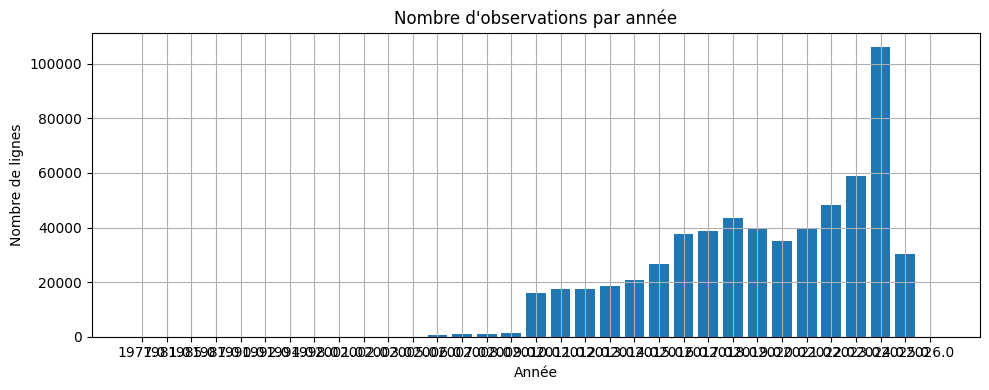

In [16]:
if "date" in df.columns:
    df["date_parsed"] = pd.to_datetime(df["date"], errors="coerce")
    year_counts = df["date_parsed"].dt.year.value_counts().sort_index()
    
    plt.figure(figsize=(10, 4))
    plt.bar(year_counts.index.astype(str), year_counts.values)
    plt.title("Nombre d'observations par année")
    plt.xlabel("Année")
    plt.ylabel("Nombre de lignes")
    plt.tight_layout()
    plt.show()
else:
    print("Pas de colonne 'date' trouvée.")

Points avec coordonnées : 583445


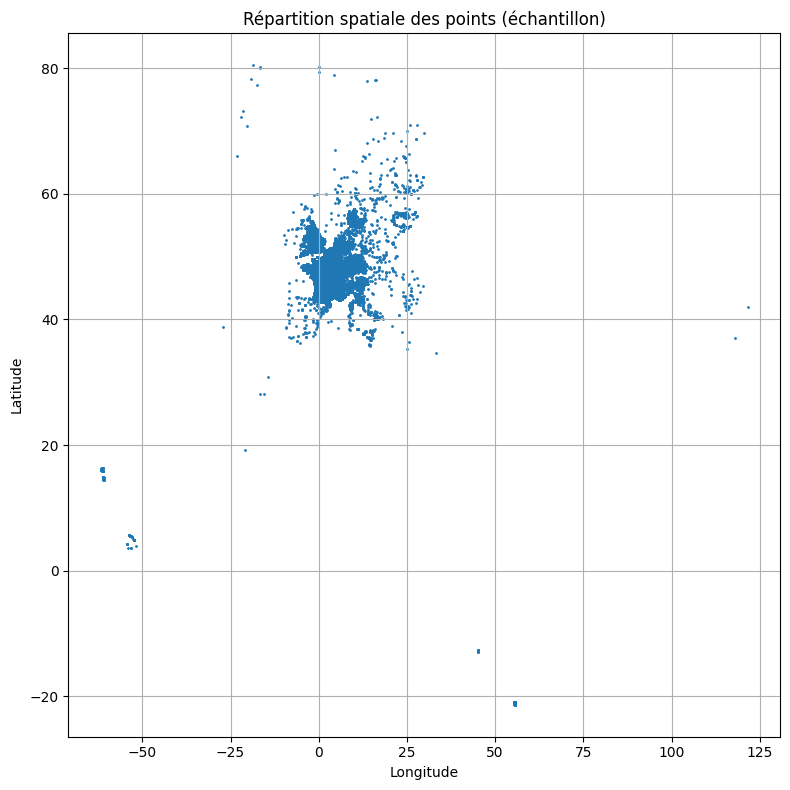

In [17]:
if {"lat", "lon"}.issubset(df.columns):
    spatial_df = df[["lat", "lon"]].dropna().copy()
    
    print("Points avec coordonnées :", len(spatial_df))
    
    # échantillon pour éviter un graphique trop lourd
    sample_size = min(50000, len(spatial_df))
    spatial_sample = spatial_df.sample(sample_size, random_state=42) if len(spatial_df) > sample_size else spatial_df
    
    plt.figure(figsize=(8, 8))
    plt.scatter(spatial_sample["lon"], spatial_sample["lat"], s=1)
    plt.title("Répartition spatiale des points (échantillon)")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.tight_layout()
    plt.show()
else:
    print("Colonnes lat/lon non trouvées.")